# Learning OpenCV

In [188]:
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np

## Read and display an image

In [189]:
# read an image
image = cv2.imread("images/image_5.jpg")

print(image.shape)

(981, 736, 3)


In [190]:
# write to an image 
cv2.imwrite(os.path.join('.','images','image_1_out.jpg'),image)

True

(np.float64(-0.5), np.float64(735.5), np.float64(980.5), np.float64(-0.5))

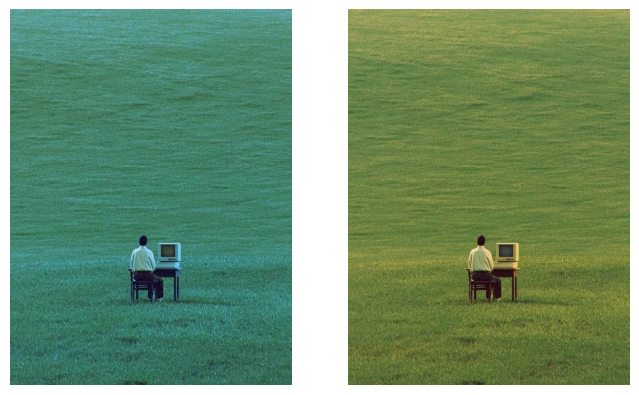

In [191]:
# visualize the image using matplotlib
fig, ax = plt.subplots(1,2, figsize=(8,8))

# change of channels 
# OpenCV reads the images as BGR but matplotplib expects RGB 

# before converting
ax[0].imshow(image)
ax[0].axis("off")

# after converting
img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
ax[1].imshow(img_rgb)
ax[1].axis("off")

(981, 736, 3)


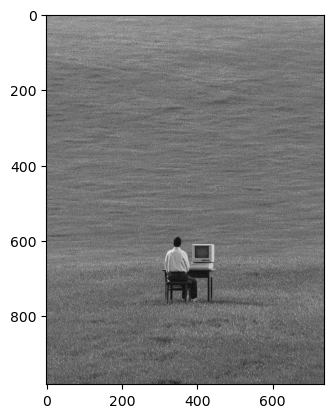

In [192]:
# lets make the image grayscale

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = cv2.cvtColor(gray, cv2.COLOR_BGR2RGB)
plt.imshow(gray)
print(gray.shape)

In [193]:
# visualize the image using cv
cv2.imshow('image',image)
cv2.waitKey(5000)
cv2.destroyAllWindows()

In [194]:
# displaying grayscale image using OpenCV
cv2.imshow("Grayscale", gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

## Read and display a Video using CV

In [195]:
# getting the path to the video
video_path = os.path.join('.','images','video_1.mp4')

In [196]:
# process to display the video
video = cv2.VideoCapture(video_path)

while True:
    ret, frame = video.read()

    if not ret:
        break

    cv2.imshow("Video", frame)

    if cv2.waitKey(60) & 0xFF == ord("q"):
        break

video.release()
cv2.destroyAllWindows()

## Read from camera

In [197]:
cam = cv2.VideoCapture(0)

while True:
    ret, frame = cam.read()

    if not ret:
        break

    cv2.imshow('frame', frame)

    if cv2.waitKey(40) & 0xFF == ord("q"):
        break

cam.release()
cv2.destroyAllWindows() 

## Image Preprocessing 

In [198]:
# Resizing

resized_image = cv2.resize(image, (500,500))
cv2.imshow('image',resized_image)
cv2.waitKey(5000)
cv2.destroyAllWindows()

In [199]:
# cropping 
print(image.shape)
# we have to manually adjust the pixels and then do the cropping
cropped_img = image[500:850,250:500]

cv2.imshow("image", image)
cv2.imshow("cropped_image", cropped_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

(981, 736, 3)


In [200]:
# Flipping the image
H_flip = cv2.flip(image, 1)
V_flip = cv2.flip(image, 0)
Both_flip = cv2.flip(image, -1)

cv2.imshow('original Image', image)
cv2.imshow('Horizontal flip',H_flip)
cv2.imshow('Vertical flip',V_flip)
cv2.imshow('Flipped both way',Both_flip)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [201]:
# Normalizing the image
# since we are provided with an unit8 just divide it with 255.0 - creates floating point values
normalized_image = image / 255.0
cv2.imshow('normalized Image', normalized_image)
cv2.imshow("Original Image", image)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [202]:
# Blurring an Image.

# 1. Simple Blur
simple_blurred = cv2.blur(image, (10,10))
cv2.imshow("simple Blur", simple_blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [203]:
# 2. gaussian BLur

gaussian_blurred  = cv2.GaussianBlur(image, (5,5), 0)
cv2.imshow("Gaussian Blur",gaussian_blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [204]:
# Median Blur

median_blur = cv2.medianBlur(image, 5)
cv2.imshow("Median Blur",median_blur)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [205]:
# Bilateral Filter

bilateral_blur = cv2.bilateralFilter(image, 9, 75, 75) # img, k, s_space, s_intensity
cv2.imshow("Bilateral Filtered Image", bilateral_blur)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [206]:
# all blurs in one
cv2.imshow("org image",image)
cv2.imshow("Median Blur",median_blur)
cv2.imshow("Bilateral Filtered Image", bilateral_blur)
cv2.imshow("Gaussian Blur",gaussian_blurred)
cv2.imshow("simple Blur", simple_blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [207]:
# loading another image
image2 = cv2.imread(os.path.join('.','images','image_2.jpg'))

In [208]:
# display the image
cv2.imshow('image 2',image2)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [209]:
# Thresholding

# Binary Thresholding
# convert the image to grayscale first
gray_img = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

cv2.imshow("grayed out", gray_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

# Apply Binary Threshold 
_, binary = cv2.threshold(
    gray_img,
    170, # threshold
    255, # value to be assigned if > Threshold (for bright pixels in thresh_binary)
    cv2.THRESH_BINARY # thresholding technique
)

cv2.imshow("Binary thresholded image",binary)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [210]:
# Adaptive Thresholding

adapt_binary = cv2.adaptiveThreshold(
    gray_img,
    255, # value to be assigned if > local Threshold
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, # adaptive method - also Mean method is also there 
    # cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY, # which thresholding technique
    51, # neighbourhood picels - (while choosing not more than foreground size)
    15 # constant c in adaptive method - (choose - c high to clean the background with black dots, c low if foreground parts are missing )
)

cv2.imshow("adaptive binary thresh", adapt_binary)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [211]:
# Otsu Thresholding

# creates histogram and calc every values from 0 - 255 's variance and then chooses the max variance one
threshold , otsu_binary = cv2.threshold(
    gray_img,
    0, # 0 means telling otsu to automatically calculate the global threshold for us 
    255, # value if > T 
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

cv2.imshow("Otsu Thresholded image", otsu_binary)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [212]:
#                   ┌─────────────────────────────┐
#                   │   Choose Threshold Method   │
#                   └──────────────┬──────────────┘
#                                  │
#          ┌───────────────────────┴───────────────────────┐
#          ▼                                               ▼
#   Even Lighting?                                  Uneven / Shadows?
#          │                                               │
#  ┌───────┴───────┐                                       ▼
#  ▼               ▼                               ┌───────────────┐
# Know exact   Let algorithm                       │   ADAPTIVE    │
#  value?       find it automatically              └───────────────┘
#  ▼               ▼                                
# ┌────────┐   ┌───────┐                            
# │ NORMAL │   │ OTSU  │                            
# └────────┘   └───────┘                            

In [213]:
# Morphological Operations

# mainly used to modify the shape/structure of objects in binary/grayscale images

# 1. Erosion - shrinks foreground regions
# it marks the origin of the structural element 1 if the kernel (SE) completely fits. i.e neighbouring pixels are the same as kernel.
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5,5))

eroded = cv2.erode(binary, kernel)

# yoiu can see the foreground (subject) has shrinked
cv2.imshow("eroded pic", eroded)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [214]:
# erosion :
# remove tiny white noise
# separate objects that are slightly connected
# shrink foreground regions
# remove thin protrusions

In [215]:
# 2. Dilation — expands foreground regions

# If at least one pixel covered by the kernel is white (255), the center pixel is turned white (255).
# The center pixel only stays black if every single pixel under the kernel is black.

kernel  = cv2.getStructuringElement(cv2.MORPH_RECT, (5,5))
dialated = cv2.dilate(binary, kernel)

# we can see the foreground has been expanded
cv2.imshow("Dialated Image", dialated)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [216]:
# Dilation can:
# Fill small gaps
# Connect nearby objects
# Fill tiny holes
# Strengthen/thicken foreground regions

In [217]:
cv2.imshow("image",binary)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [218]:
# 3. Opening — erosion → dilation
opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel
)

# Erosion removes the tiny dots:
# Then dilation restores the main object's approximate size.
# So opening is mainly useful for removing small foreground noise.

cv2.imshow("Morph opened image",opening)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [219]:
# 4. Closing — dilation → erosion
closing = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel
)

# Here we first expand the foreground, which can:
# fill small black holes
# close small gaps
# connect nearby foreground regions
# Then erosion brings the object's size back.

cv2.imshow("Morph closed image",closing)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [220]:
# Erosion   → shrink
# Dilation  → expand
# Opening   → erosion → dilation → remove small white noise
# Closing   → dilation → erosion → fill small black gaps/holes

## Edge Detection

In [221]:
# 1. Sobel Technique
gray_2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray_2, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_2, cv2.CV_64F, 0, 1, ksize=3)

# gray      → input grayscale image
# CV_64F    → output data type
# 1         → dx: derivative in X direction (change of intensity in pixel values)
# 0         → dy: derivative in Y direction
# ksize=3   → 3×3 Sobel kernel

sobel_x = cv2.convertScaleAbs(sobel_x)
sobel_y = cv2.convertScaleAbs(sobel_y)

sobel = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)
# Output = (src1 *alpha )+(src2 * beta )+gamma

cv2.imshow("edged image",sobel)
cv2.imshow("original image",gray_2)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [222]:
# Laplacian - uses single kernel to calc the second-order derivative
import numpy as np

laplacian = cv2.Laplacian(gray_2, cv2.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

cv2.imshow("image",laplacian)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [223]:
# Canny - 

# 1. Gaussian Blur
#        ↓
#    remove noise

# 2. Sobel Gradients
#        ↓
#    Gx, Gy

# 3. Magnitude + Direction
#        ↓
#    strength + orientation

# 4. Non-Maximum Suppression
#        ↓
#    make edges thin

# 5. Double Threshold
#        ↓
#    strong / weak / discard

# 6. Hysteresis
#        ↓
#    keep connected weak edges

edges = cv2.Canny(gray_2, 100,200)

cv2.imshow("Canny edged image",edges)
cv2.imshow("original image", gray_2)
cv2.waitKey(0)
cv2.destroyAllWindows()

## Data Augmentation

In [224]:
# Rotation
height, width = image.shape[:2]

center = (width // 2, height // 2)

M = cv2.getRotationMatrix2D(center, 45, 1) # 45 - degree, 1 - scale - Transformation Matrix

rotated = cv2.warpAffine(image, M, (width, height)) # applies the transformation matrix by doing dot product

cv2.imshow("image",rotated)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [225]:
M = cv2.getRotationMatrix2D(center, 45, 1) # 45 - degree, 1 - scale
print(M)
# M=[ cosθ ​sinθ tx
#    −sinθ cosθ​ ​ty​​]
# t - translation 
# sin and cos is responsible for rotation

[[   0.70710678    0.70710678 -238.69761826]
 [  -0.70710678    0.70710678  403.7329727 ]]


In [226]:
# Translation - moving the image left/right or up/down
M = np.float32([
    [1, 0, 100], # + means right - means left
    [0, 1, 50] # + means down and - means up 
])

translated = cv2.warpAffine(
    image,
    M,
    (image.shape[1], image.shape[0])
)

cv2.imshow("translated Image", translated)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [227]:
# Scaling / Zooming
scaled_zoom = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
# fx=2 → width × 2 , fx > 1  → enlarge
# fy=2 → height ×  , 2fx < 1  → shrink
scaled_out = cv2.resize(image, None, fx=0.5, fy=0.5)

cv2.imshow("Zoomed in Image", scaled_zoom)
cv2.imshow("Zoomed out Image", scaled_out)
cv2.waitKey(0)
cv2.destroyAllWindows()

interpolation is essentially the process of estimating or calculating the value of a pixel for example : when we do all these data augmentations it is essentially coordinate transformations right, so when we do this the image tends not to land on integer pixels and may end up different places so interpolation helps to smooth out the image and maintain the picture, it also helps in scaling as we are increasing the distance betweem the coordinates of the pixels it calculates what value the pixels in between shall have

In [228]:
# Perspective Transformation
src = np.float32([
    [100, 100],   # top-left
    [500, 120],   # top-right
    [520, 400],   # bottom-right
    [80, 380]     # bottom-left
])

dst = np.float32([
    [0, 0],
    [400, 0],
    [400, 300],
    [0, 300]
])

M = cv2.getPerspectiveTransform(src, dst)

result = cv2.warpPerspective(image, M, (400, 300))

cv2.imshow("result", result)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [243]:
# Brightness and Contrast Adjustment
bright = cv2.convertScaleAbs(image, alpha=1, beta=100)
contrast = cv2.convertScaleAbs(image, alpha=1.5, beta=0)

# I=αI+β

cv2.imshow("bright image",bright)
cv2.imshow("contrast image", contrast)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [230]:
# Adding Synthetic Noise
noise = np.random.normal(0, 25, image.shape)

noisy = image + noise

noisy = np.clip(noisy, 0, 255).astype(np.uint8)

cv2.imshow("Original Image", image)
cv2.imshow("Noisy Image", noisy)
cv2.waitKey(0)
cv2.destroyAllWindows()

## Advanced Techniques

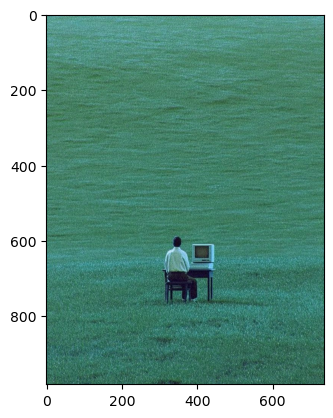

In [231]:
# just to know the coordinates
plt.imshow(image)

In [232]:
modified = image.copy()
# changes the pixel values so the image will be overwritten
modified = cv2.rectangle(modified, (100, 100), (400, 300), (0, 255, 0), 2)
# (100,100) → top-left corner
# (400,300) → bottom-right corner
# (0,255,0) → BGR color → green
# 2         → thickness (-1 for full)

modified = cv2.circle(modified, (300,200), 50, (255,0,0), 2)
# (300,200) - center
# 50 - radius

cv2.line(modified, (500,200),(200,850), (0,0,255), 2)

cv2.putText(modified, "Hi", (200,800), cv2.FONT_HERSHEY_PLAIN, 10, (255,0,0), 2)
# 10 - scale
# 2 - thickness

cv2.imshow("mod",modified)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [233]:
# Layering
# resize the images before layering it on top
resized_img2 = cv2.resize(image2, (736, 981))
# Foreground - F , Background = B
# O=αF+(1−α)B​
layered = cv2.addWeighted(resized_img2, 0.3,image, 0.7, 0)
# foreground, weight, background, weight, 0 - scalar value added to adjust the brightness 
cv2.imshow("layered", layered)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [234]:
# # Transpracy
# # [B,G,R,A] A - transparency
# # A = 0    → completely transparent
# # A = 255  → completely opaque
# # A = 128  → roughly 50% transparent
# background = cv2.imread("background.jpg")
# logo = cv2.imread("logo.png", cv2.IMREAD_UNCHANGED)
# H, W = background.shape[:2]
# h, w = logo.shape[:2]
# margin = 20
# x = W - w - margin
# y = margin
# roi = background[y:y+h, x:x+w]
# alpha = logo[:, :, 3] / 255.0
# for c in range(3):
#     roi[:, :, c] = (
#         alpha * logo[:, :, c] +
#         (1 - alpha) * roi[:, :, c]
#     )
# background[y:y+h, x:x+w] = roi

In [235]:
overlay = cv2.imread("images/image_8.jpg", cv2.IMREAD_UNCHANGED)
overlay.shape # does not have an alpha channel

(977, 736, 3)

In [236]:
# Contours and Shape Matching
obj_img = cv2.imread(os.path.join('.','images','obj_detection.jpg'))
gray_3 = cv2.cvtColor(obj_img, cv2.COLOR_BGR2GRAY)
_, binary_2 = cv2.threshold(gray_3, 130, 255, cv2.THRESH_BINARY_INV)

contours, hierarchy = cv2.findContours(
    binary_2,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
contoured_image = cv2.drawContours(obj_img,contours,-1,(0,255,0),2)
cv2.imshow("Contours", contoured_image)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [237]:
# Shape Matching
img1 = cv2.imread("shape_full.jpg")
img2 = cv2.imread("shape_square.png")

_, thresh1 = cv2.threshold(img1, 127, 255, cv2.THRESH_BINARY)
_, thresh2 = cv2.threshold(img2, 127, 255, cv2.THRESH_BINARY)

contours1, _ = cv2.findContours(thresh1, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours2, _ = cv2.findContours(thresh2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

score = cv2.matchShapes(
    contours1,
    contours2,
    cv2.CONTOURS_MATCH_I1,
    0.0
)

if score < 0.1:
    print(f"Match found! Score: {score}")
else:
    print(f"Not a match. Score: {score}")
# print("Shape similarity:", score)

Match found! Score: 0.0


In [238]:
org_image = cv2.imread("images/shapes.jpg")
template = cv2.imread("images/shapes_star.jpg")

template = cv2.resize(template, (100,100))

result = cv2.matchTemplate(
    org_image,
    template,
    cv2.TM_CCOEFF
)

min_v, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

x, y = max_loc
h,w = template.shape[:2] # rows , cols - height , width
cv2.rectangle(
    org_image,
    (x, y),
    (x + w, y + h),
    (0, 255, 0),
    2
)

print("Similarity:", max_val)
print("Location:", max_loc)

cv2.imshow("template matching", org_image)
cv2.waitKey(0)
cv2.destroyAllWindows()

Similarity: 237340320.0
Location: (503, 330)
